# Задача регрессии (деревья решений)

Загрузка данных

In [ ]:
from google.colab import files


uploaded = files.upload()

for fn in uploaded.keys():
 print('User uploaded file "{name}" with length {length} bytes'.format(
 name=fn, length=len(uploaded[fn])))


Upload widget is only available when the cell has been executed in the
 current browser session. Please rerun this cell to enable.

Saving diamonds.csv to diamonds.csv
User uploaded file "diamonds.csv" with length 35572 bytes


Импорт необходимых модулей

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Разведочный анализ датасета и визуализация данных

Считывание данных в датафрейм, информация о нем и просмотр его верхней части

In [ ]:
df = pd.read_csv('diamonds.csv', sep=",", encoding='utf_8')
df.info()


RangeIndex: 1078 entries, 0 to 1077
Data columns (total 7 columns):
 # Column Non-Null Count Dtype 
--- ------ -------------- ----- 
 0 carat 1078 non-null float64
 1 depth 1078 non-null float64
 2 table 1078 non-null float64
 3 price 1078 non-null int64 
 4 x 1078 non-null float64
 5 y 1078 non-null float64
 6 z 1078 non-null float64
dtypes: float64(6), int64(1)
memory usage: 59.1 KB


In [ ]:
df.head(20)

carat depth table price x y z
0 0.53 61.2 56.0 1655 5.22 5.25 3.20
1 0.30 62.2 57.0 411 4.27 4.28 2.66
2 0.70 61.2 56.0 4000 5.72 5.75 3.51
3 0.54 62.6 58.0 1042 5.16 5.22 3.25
4 1.01 61.2 57.5 7277 6.43 6.45 3.94
5 1.00 62.9 55.0 6871 6.40 6.36 4.01
6 0.41 61.8 55.0 1153 4.80 4.75 2.95
7 0.73 62.1 58.0 2395 5.75 5.81 3.59
8 0.30 61.8 55.0 813 4.33 4.35 2.68
9 1.90 67.1 64.0 8576 7.57 7.52 5.06
10 2.32 62.0 57.0 17676 8.49 8.45 5.25
11 0.43 61.9 57.0 716 4.83 4.86 3.00
12 1.22 63.5 56.0 5329 6.79 6.75 4.30
13 0.51 57.9 63.0 1760 5.24 5.39 3.08
14 0.32 63.2 54.0 756 4.38 4.36 2.76
15 1.00 62.7 59.0 5292 6.40 6.36 4.00
16 1.07 62.2 55.0 5325 6.54 6.58 4.08
17 1.36 62.1 55.0 11793 7.18 7.13 4.44
18 0.91 63.1 58.0 4512 6.12 6.17 3.88
19 0.71 63.3 55.0 1881 5.62 5.66 3.57

Просмотр нижней части датафрейма

In [ ]:
df.tail(n=10)

carat depth table price x y z
1068 1.07 62.4 59.0 5498 6.53 6.46 4.05
1069 1.27 61.7 56.0 11002 7.03 6.90 4.30
1070 2.12 62.1 56.0 14503 8.17 8.25 5.10
1071 0.70 62.8 57.0 2553 5.66 5.68 3.56
1072 0.30 61.5 56.0 911 4.37 4.31 2.67
1073 1.13 59.4 62.0 3967 6.78 6.83 4.04
1074 0.30 63.4 56.0 614 4.26 4.29 2.71
1075 0.30 63.1 57.0 552 4.27 4.29 2.70
1076 1.01 67.1 59.0 2942 6.27 6.19 4.18
1077 1.04 60.1 58.0 3392 6.65 6.56 3.97

Вывод описательной статистики по датасету

In [ ]:
df.describe()

carat depth table price x \
count 1078.000000 1078.000000 1078.000000 1078.000000 1078.000000 
mean 0.786911 61.732746 57.510668 3770.916512 5.721447 
std 0.444856 1.374132 2.247836 3617.987090 1.073285 
min 0.230000 55.000000 52.000000 357.000000 3.880000 
25% 0.400000 61.000000 56.000000 966.000000 4.740000 
50% 0.710000 61.800000 57.000000 2466.000000 5.710000 
75% 1.030000 62.400000 59.000000 5272.750000 6.520000 
max 2.580000 68.000000 66.000000 18766.000000 8.710000 

 y z 
count 1078.000000 1078.000000 
mean 5.722904 3.532727 
std 1.065218 0.668290 
min 3.890000 2.360000 
25% 4.740000 2.930000 
50% 5.740000 3.530000 
75% 6.510000 4.020000 
max 8.660000 5.570000

Парные диаграммы

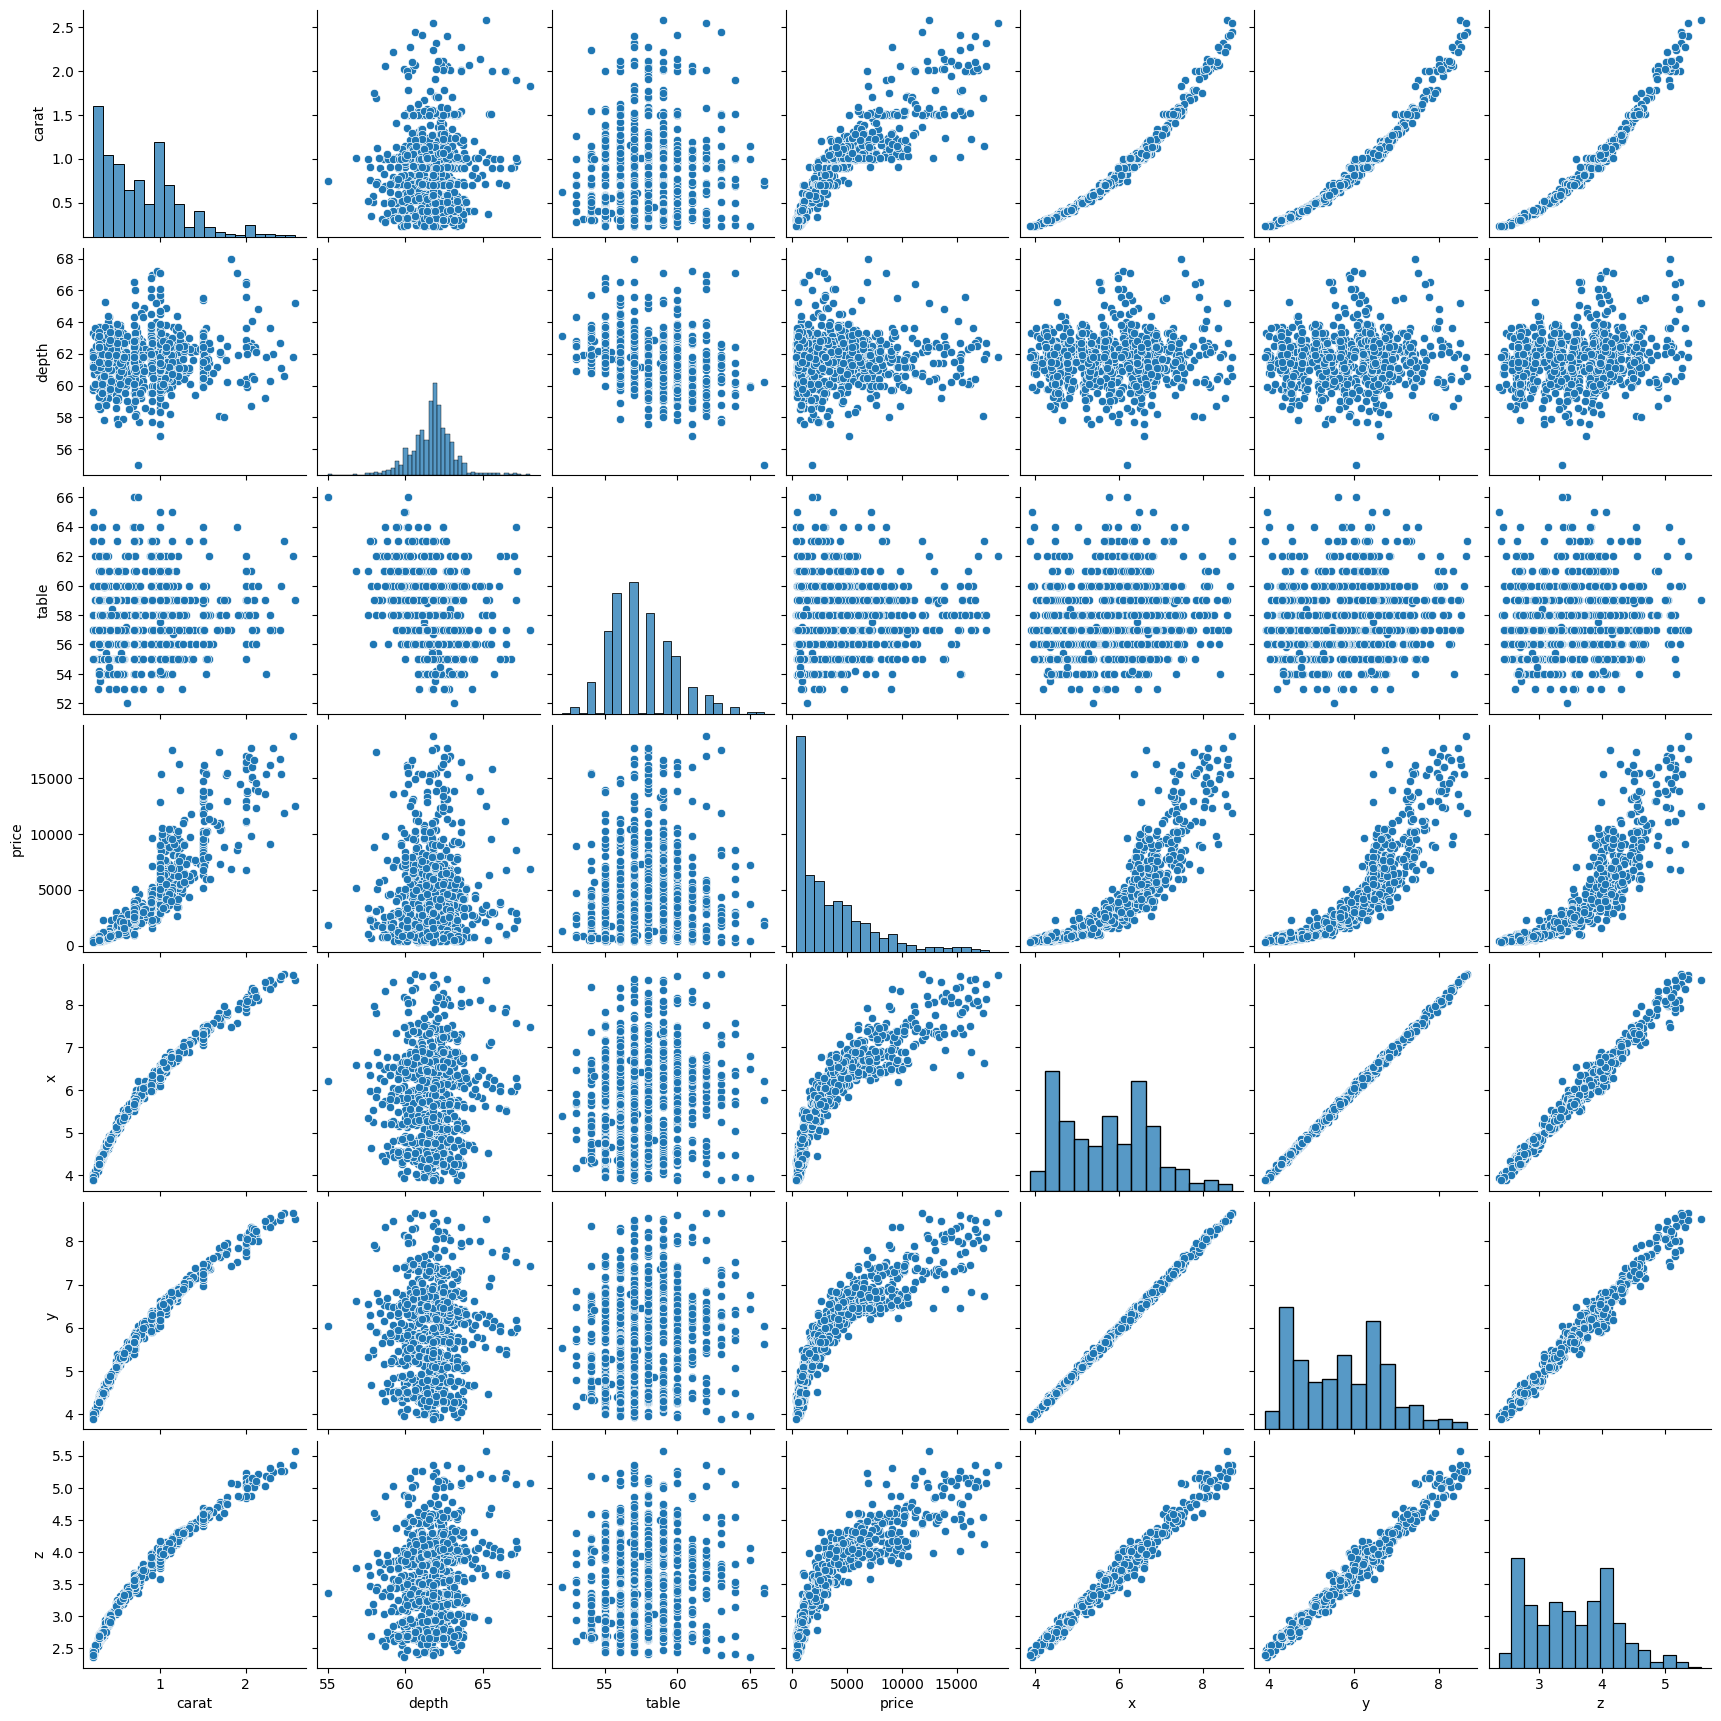

In [ ]:
plt.figure(figsize=(15,15), dpi=90)
sns.pairplot(df, kind="scatter")

Корреляционная матрица

In [ ]:
df.corr(method='pearson')


carat depth table price x y z
carat 1.000000 0.098347 0.196237 0.908956 0.977541 0.976262 0.978113
depth 0.098347 1.000000 -0.278756 0.027811 0.036476 0.032294 0.158280
table 0.196237 -0.278756 1.000000 0.150988 0.198708 0.195293 0.162084
price 0.908956 0.027811 0.150988 1.000000 0.877117 0.878059 0.870141
x 0.977541 0.036476 0.198708 0.877117 1.000000 0.998870 0.991919
y 0.976262 0.032294 0.195293 0.878059 0.998870 1.000000 0.991360
z 0.978113 0.158280 0.162084 0.870141 0.991919 0.991360 1.000000

Диаграмма корреляции

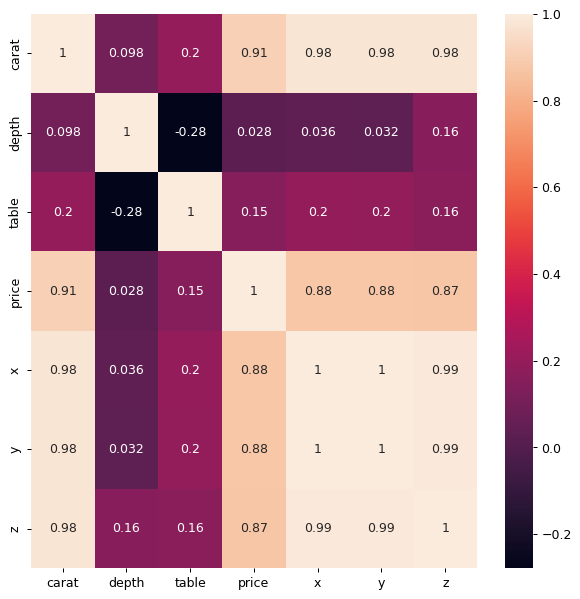

In [ ]:
plt.figure(figsize=(8,8), dpi=90)
sns.heatmap(df.corr(), xticklabels=df.corr().columns, yticklabels=df.corr().columns, annot=True)

# Деревья решений

![Дерево решений](https://studref.com/im/13/5014/398643-20.jpg)

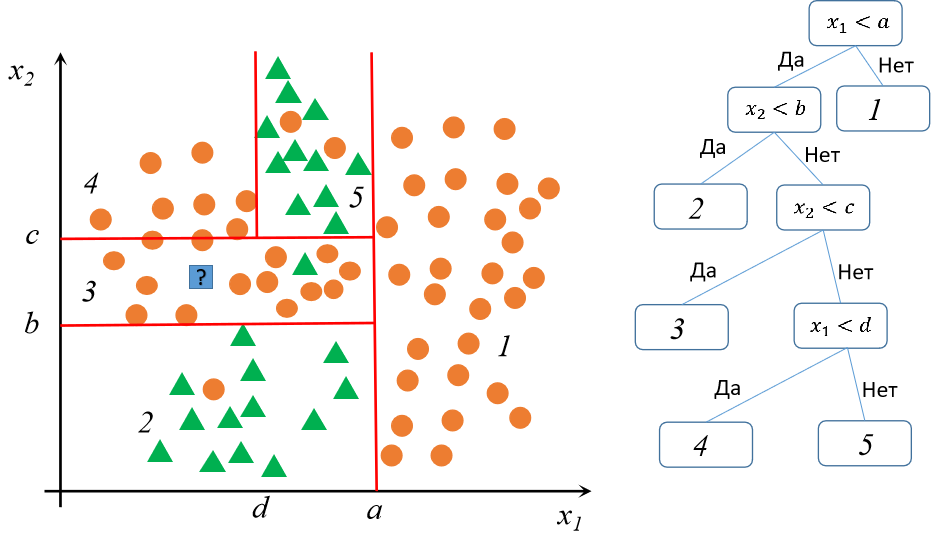



Построение модели деревьев решений и предсказание с ее помощью

In [ ]:
X = df.drop("price", axis=1)
X.head()

carat depth table x y z
0 0.53 61.2 56.0 5.22 5.25 3.20
1 0.30 62.2 57.0 4.27 4.28 2.66
2 0.70 61.2 56.0 5.72 5.75 3.51
3 0.54 62.6 58.0 5.16 5.22 3.25
4 1.01 61.2 57.5 6.43 6.45 3.94

In [ ]:
y = df.price
y

0 1655
1 411
2 4000
3 1042
4 7277
 ... 
1073 3967
1074 614
1075 552
1076 2942
1077 3392
Name: price, Length: 1078, dtype: int64

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.30)

In [ ]:
from sklearn.tree import DecisionTreeRegressor
model=DecisionTreeRegressor(random_state=42,max_depth=5)
model.fit(X_train,y_train)
y_pred = model.predict(X_test)
#for i in range (len(y_pred)): print("i=", i," | y_pred=", y_pred[i]," | y_test=", y_test[i], " | y_pred - y_test=", y_pred[i] - y_test[i])


Оценим качество предсказания модели деревьев решений

In [ ]:
from sklearn.metrics import mean_squared_error
print ('RMSE=', np.sqrt(mean_squared_error(y_pred,y_test)))

RMSE= 1742.3287861208837


**Ансамблевые методы. RandomForest - случаный лес**

В 1906 году известный британский ученый Френсис Гальтон попал на сельскую ярмарку, на которой в качестве развлечения посетителям предлагалось на глаз оценить вес выставленного на всеобщее обозрение быка и написать эту цифру на специальном билете. За правильные ответы организаторы шоу обещали призы. В результате в голосовании приняли участие около 800 человек — как заядлых фермеров, так и людей, далеких от скотоводческих дел. Собрав после этой ярмарки все билеты для анализа, Гальтон высчитал среднее арифметическое значение для всей выборки — 1197 фунтов. Реальный же вес быка оказался 1198 фунтов. Каким-то непостижимым образом разношерстная публика дала ответ, максимально приближенный к реальному показателю.

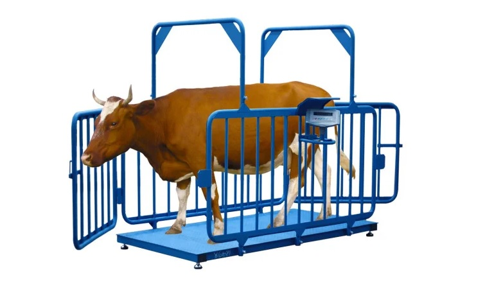

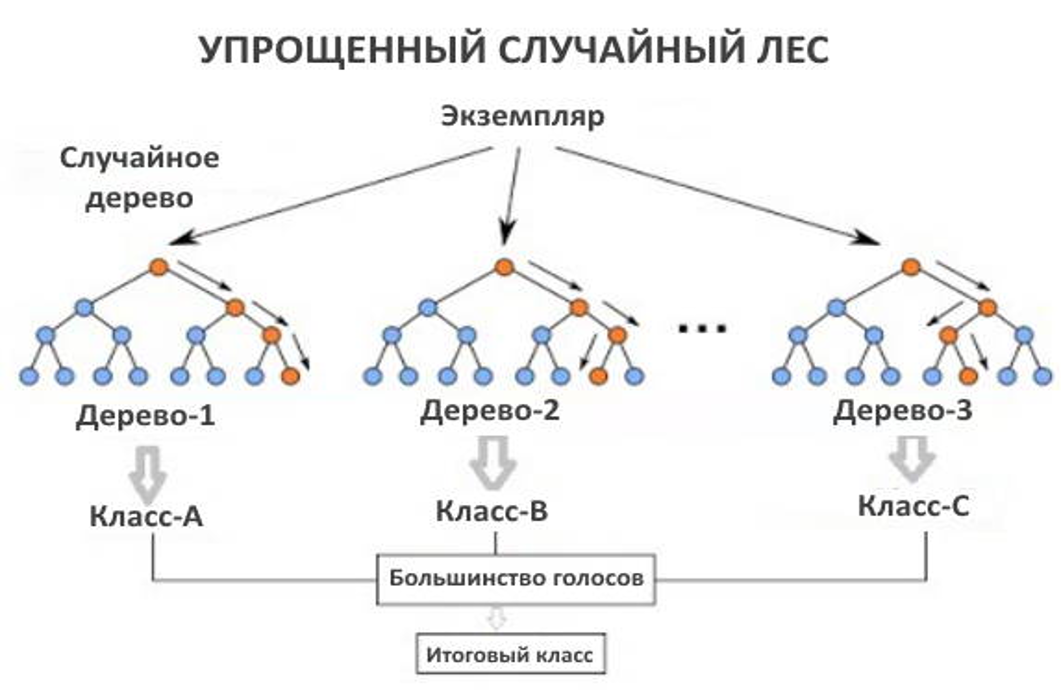

Построение модели случаного леса и предсказание с ее помощью

In [ ]:
from sklearn.ensemble import RandomForestRegressor
model1 = RandomForestRegressor(n_estimators=30,
 oob_score=True,
 random_state=1)
model1.fit(X_train, y_train)
y_pred = model1.predict(X_test)


#for i in range (len(y_pred)): print("i=", i," | y_pred=", y_pred[i]," | y_test=", y_test[i], " | y_pred - y_test=", y_pred[i] - y_test[i])

Оценка качества предсказания модели RF



In [ ]:
print ('RMSE=', np.sqrt(mean_squared_error(y_pred,y_test)))

RMSE= 1600.2553859613638


**Градиентный бустинг**

Общая идея алгоритмов бустинга - последовательно применять предикторы так, чтобы каждая последующая модель минимизировала ошибку предыдущей.

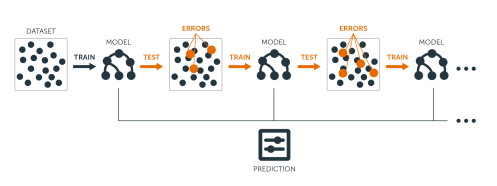

Построение модели XGBoost

In [ ]:
import xgboost
model = xgboost.XGBRegressor(learning_rate=0.07, max_depth=5,iterations=100,seed=0)
model.fit(X_train,y_train)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [12:25:29] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "iterations" } are not used.

 bst.update(dtrain, iteration=i, fobj=obj)


XGBRegressor(base_score=None, booster=None, callbacks=None,
 colsample_bylevel=None, colsample_bynode=None,
 colsample_bytree=None, device=None, early_stopping_rounds=None,
 enable_categorical=True, eval_metric=None, feature_types=None,
 feature_weights=None, gamma=None, grow_policy=None,
 importance_type=None, interaction_constraints=None, iterations=100,
 learning_rate=0.07, max_bin=None, max_cat_threshold=None,
 max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
 max_leaves=None, min_child_weight=None, missing=nan,
 monotone_constraints=None, multi_strategy=None, n_estimators=None,
 n_jobs=None, ...)

Предсказание с помощью XGBoost

In [ ]:
y_pred = model.predict (X_test)
#for i in range (len(y_pred)): print("i=", i," | y_pred=", y_pred[i]," | y_test=", y_test[i], " | y_pred - y_test=", y_pred[i] - y_test[i])


Оценка качества предсказания XGBoost

In [ ]:
print ('RMSE=', np.sqrt(mean_squared_error(y_pred,y_test)))

RMSE= 1588.429727750019


Построение модели CatBoost и предсказание с ее помощью

In [ ]:
!pip install catboost

 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.6 MB/s eta 0:00:00


In [ ]:

from catboost import CatBoostRegressor

model2 = CatBoostRegressor(iterations=346, learning_rate=0.05, depth=5)
# Fit model
model2.fit(X_train, y_train)
# Get predictions
y_pred = model2.predict(X_test)

0:	learn: 3478.5896084	total: 53.1ms	remaining: 18.3s
1:	learn: 3352.5968080	total: 54.5ms	remaining: 9.37s
2:	learn: 3229.4255588	total: 58.4ms	remaining: 6.67s
3:	learn: 3111.7581507	total: 62.9ms	remaining: 5.38s
4:	learn: 3001.2538099	total: 66.2ms	remaining: 4.51s
5:	learn: 2893.7589942	total: 69.4ms	remaining: 3.93s
6:	learn: 2792.9540414	total: 70.6ms	remaining: 3.42s
7:	learn: 2700.4909108	total: 73.9ms	remaining: 3.12s
8:	learn: 2614.4801251	total: 76.9ms	remaining: 2.88s
9:	learn: 2536.2581131	total: 78.3ms	remaining: 2.63s
10:	learn: 2456.6201734	total: 83ms	remaining: 2.53s
11:	learn: 2381.5541092	total: 90.4ms	remaining: 2.51s
12:	learn: 2313.9921735	total: 93.7ms	remaining: 2.4s
13:	learn: 2249.0469979	total: 97.1ms	remaining: 2.3s
14:	learn: 2185.2962235	total: 98.3ms	remaining: 2.17s
15:	learn: 2127.6851861	total: 102ms	remaining: 2.1s
16:	learn: 2073.9755297	total: 105ms	remaining: 2.03s
17:	learn: 2020.5305979	total: 108ms	remaining: 1.97s
18:	learn: 1972.7949869	tota

Оценка качества модели CatBoost

In [ ]:
print ('RMSE=', np.sqrt(mean_squared_error(y_pred,y_test)))

RMSE= 1531.668350037224
